# Ablation Study — Result Comparison Tables

Produces **all result comparison tables** for the thesis ablation study, exported as:
- Individual `.tex` files (one per table)
- A **single merged PDF** containing every table in sequence

### Tables produced
| # | Table | Content |
|---|-------|---------|
| 1 | `tab_main` | Main results: harmonic & arithmetic subset-mean F / P / R for all 7 experiments |
| 2 | `tab_delta` | Δ vs Baseline: absolute and relative gains |
| 3 | `tab_postproc` | No-postproc vs best-postproc F-measure + postproc gain |
| 4 | `tab_per_species` | Per-species F-measure (rows=species, cols=experiments) |
| 5 | `tab_per_file` | Per-file TP / FP / FN / P / R / F for the winning experiment |
| 6 | `tab_masking_phases` | Masking-only experiments (Phases 1–3 + AFRI) vs Baseline |
| 7 | `tab_config` | Experiment configuration summary (for thesis appendix) |

### Prerequisites
```
pip install pandas matplotlib fpdf2 pylatex
```
PDF merging uses `matplotlib` backends only — no external LaTeX installation required.

---
## 0 — Configuration
**Edit `EXPERIMENT_LOGS` to point to the `stdout.log` for each run.**
Leave any entry as `None` to skip that experiment gracefully.

In [1]:
import sys
from pathlib import Path

# ── Import shared log parser ───────────────────────────────────────────────
NOTEBOOKS_DIR = Path(".").resolve()
sys.path.insert(0, str(NOTEBOOKS_DIR))
import parse_logs as pl

# ── Point each key to the stdout.log for that experiment run ──────────────
# Example path pattern:
#   ../logs/experiments/runs/<exp_name>/<YYYY-MM-DD_HH-MM-SS>/stdout.log
EXPERIMENT_LOGS = {
    "Baseline":            "/home/helios/Downloads/run_logs/baseline.log",  # e.g. "../logs/experiments/runs/baseline/2026-.../stdout.log"
    "CIFE":                "/home/helios/Downloads/run_logs/CIFE.log",
    "Phase 1 (Random)":    "/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/baselines/dcase2024_task5/logs/experiments/runs/ablation_experiments_aggressive/2026-07-08_20-16-22/stdout.log",
    "Phase 2 (Energy)":    "/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/baselines/dcase2024_task5/logs/experiments/runs/ablation_experiments_aggressive/2026-07-09_02-57-24/stdout.log",
    "Phase 3 (Activation)": "/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/baselines/dcase2024_task5/logs/experiments/runs/ablation_experiments_aggressive/2026-07-09_09-07-44/stdout.log",
    "Phase 3 + AFRI (Direct)": "/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/baselines/dcase2024_task5/logs/experiments/runs/ablation_experiments_aggressive/2026-07-09_15-20-24/stdout.log",
    "Phase 4 + AFRI (Inverse)": "/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/baselines/dcase2024_task5/logs/experiments/runs/ablation_experiments_aggressive/2026-07-09_21-26-47/stdout.log",
}


# ── Output directory for .tex files and the merged PDF ────────────────────
OUTPUT_DIR = Path("ablation_tables")
OUTPUT_DIR.mkdir(exist_ok=True)

PDF_OUTPUT = OUTPUT_DIR / "ablation_results_all_tables.pdf"

# ── Filter None entries ────────────────────────────────────────────────────
logs_to_parse = {k: v for k, v in EXPERIMENT_LOGS.items() if v is not None}
print(f"Configured experiments : {len(EXPERIMENT_LOGS)}")
print(f"Logs available to parse: {len(logs_to_parse)}")
if len(logs_to_parse) == 0:
    print("\n⚠  No logs configured. Tables will be built with placeholder NaN values.")
    print("   Fill in EXPERIMENT_LOGS above and re-run.")

Configured experiments : 7
Logs available to parse: 7


---
## 1 — Load & Parse Logs

In [2]:
import pandas as pd
import numpy as np

# Parse all available logs
experiments = pl.load_experiments(logs_to_parse)

# Build core DataFrames
df_final   = pl.final_results_df(experiments)    # one row per experiment, final scores
df_nopost  = pl.no_postproc_df(experiments)      # (experiment, k, scores)
df_perfile = pl.per_file_df(experiments)         # per-file TP/FP/FN from winning block

# ── Reindex to configured order (fills missing experiments with NaN) ───────
exp_order = list(EXPERIMENT_LOGS.keys())
df_final = df_final.reindex(exp_order)

print("\ndf_final shape:", df_final.shape)
print("Columns:", list(df_final.columns))
df_final

  ✓ Baseline                        fmeasure=16.741
  ✓ CIFE                            fmeasure=15.217
  ✓ Phase 1 (Random)                fmeasure=15.489
  ✓ Phase 2 (Energy)                fmeasure=15.443
  ✓ Phase 3 (Activation)            fmeasure=15.447
  ✓ Phase 3 + AFRI (Direct)         fmeasure=15.452
  ✓ Phase 4 + AFRI (Inverse)        fmeasure=15.458

df_final shape: (7, 6)
Columns: ['precision', 'recall', 'fmeasure', 'precisionavg', 'recallavg', 'fmeasureavg']


,precision,recall,fmeasure,precisionavg,recallavg,fmeasureavg
experiment,,,,,,
Baseline,0.118848,0.283061,16.741,0.285953,0.537623,28.712
CIFE,0.128235,0.187088,15.217,0.290641,0.521227,29.344
Phase 1 (Random),0.118082,0.225040,15.489,0.272584,0.523698,27.737
Phase 2 (Energy),0.105124,0.290834,15.443,0.251769,0.546213,27.364
Phase 3 (Activation),0.116407,0.229527,15.447,0.268126,0.524667,27.672
Phase 3 + AFRI (Direct),0.106729,0.279844,15.452,0.255331,0.540738,27.547
Phase 4 + AFRI (Inverse),0.106778,0.279844,15.458,0.255341,0.540738,27.548


---
## 2 — Shared Helpers

In [3]:
import matplotlib.pyplot as plt
import matplotlib.backends.backend_pdf as pdf_backend
import textwrap

# ── Collected (fig, title) tuples — appended per table, merged at the end ─
PDF_PAGES: list = []

# ── Colour palette ─────────────────────────────────────────────────────────
COLORS = plt.cm.tab10.colors

plt.rcParams.update({
    "figure.dpi": 150,
    "font.family": "serif",
    "font.size": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.alpha": 0.35,
})

# ── LaTeX table wrapper ────────────────────────────────────────────────────
def save_latex(df: pd.DataFrame, filename: str, caption: str, label: str,
               float_fmt: str = "%.2f", bold_best_col: str = None) -> str:
    """
    Write df to OUTPUT_DIR/<filename>.tex.
    Optionally bolds the cell with the highest value in `bold_best_col`.
    Returns the LaTeX string.
    """
    df_out = df.copy()

    # Bold the maximum in one column
    if bold_best_col and bold_best_col in df_out.columns:
        best_idx = df_out[bold_best_col].idxmax(skipna=True)
        def bold_best(val, idx):
            if idx == best_idx and pd.notna(val):
                return f"\\textbf{{{val:{float_fmt[1:]}}}}"  # strip the % prefix
            return f"{val:{float_fmt[1:]}}" if pd.notna(val) else "—"
        df_out[bold_best_col] = [
            bold_best(v, i) for v, i in zip(df_out[bold_best_col], df_out.index)
        ]

    latex = df_out.to_latex(
        float_format=float_fmt,
        na_rep="—",
        caption=caption,
        label=label,
        escape=False,   # allow \textbf{} in cells
    )

    out_path = OUTPUT_DIR / filename
    out_path.write_text(latex, encoding="utf-8")
    print(f"  ✓ LaTeX written → {out_path}")
    return latex


def table_to_figure(df: pd.DataFrame, title: str,
                    col_widths: list = None,
                    highlight_col: str = None) -> plt.Figure:
    """
    Render a DataFrame as a matplotlib Table figure.
    Highlights the max cell in `highlight_col` with a light-green background.
    Returns the Figure (not shown — caller decides).
    """
    df_r = df.copy()

    # Format numbers
    def fmt(v):
        if pd.isna(v): return "—"
        if isinstance(v, float): return f"{v:.2f}"
        return str(v)

    cell_text = [[fmt(v) for v in row] for row in df_r.values]
    row_labels = [str(i) for i in df_r.index]
    col_labels = list(df_r.columns)

    n_rows = len(df_r)
    n_cols = len(col_labels)
    fig_h = max(2.0, 0.35 * (n_rows + 2))
    fig_w = max(6.0, 1.2 * n_cols)

    fig, ax = plt.subplots(figsize=(fig_w, fig_h))
    ax.axis("off")

    tbl = ax.table(
        cellText=cell_text,
        rowLabels=row_labels,
        colLabels=col_labels,
        loc="center",
        cellLoc="center",
    )
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(8)

    if col_widths:
        for ci, w in enumerate(col_widths):
            for ri in range(-1, n_rows):
                tbl[ri, ci].set_width(w)

    # Header row style
    for ci in range(n_cols):
        tbl[0, ci].set_facecolor("#dce6f1")
        tbl[0, ci].set_text_props(weight="bold")

    # Highlight best in one column
    if highlight_col and highlight_col in df_r.columns:
        hcol_idx = list(df_r.columns).index(highlight_col)
        best_ri  = df_r[highlight_col].values
        valid    = [v for v in best_ri if pd.notna(v)]
        if valid:
            best_val = max(valid)
            for ri, v in enumerate(best_ri):
                if pd.notna(v) and v == best_val:
                    tbl[ri, hcol_idx].set_facecolor("#c6efce")

    # Alternating row shading
    for ri in range(n_rows):
        bg = "#f7f7f7" if ri % 2 == 0 else "white"
        for ci in range(n_cols):
            if tbl[ri, ci].get_facecolor() == (1, 1, 1, 1) or \
               list(tbl[ri, ci].get_facecolor()) == [1., 1., 1., 1.]:
                tbl[ri, ci].set_facecolor(bg)

    ax.set_title(title, fontsize=10, fontweight="bold", pad=6)
    plt.tight_layout()
    return fig


print("Helpers defined.")

Helpers defined.


---
## Table 1 — Main Results
F-measure, Precision and Recall for all 7 experiments, each aggregated over the six reference subsets two ways: harmonic mean (`harm.`, the official DCASE metric) and arithmetic mean (`arith.`).

,F (harm.),P (harm.),R (harm.)
experiment,,,
Baseline,16.74,11.88,28.31
CIFE,15.22,12.82,18.71
Phase 1 (Random),15.49,11.81,22.50
Phase 2 (Energy),15.44,10.51,29.08
Phase 3 (Activation),15.45,11.64,22.95
Phase 3 + AFRI (Direct),15.45,10.67,27.98
Phase 4 + AFRI (Inverse),15.46,10.68,27.98


  ✓ LaTeX written → ablation_tables/tab_main.tex
\begin{table}
\centering
\caption{Main ablation results on DCASE 2024 Task 5 validation set. All values on a 0--100 scale. Bold = highest F-measure (harmonic subset mean).}
\label{tab:main_results}
\begin{tabular}{llrr}
\toprule
{} &       F (harm.) &  P (harm.) &  R (harm.) \\
experiment               &                 &            &            \\
\midrule
Baseline                 &  \textbf{16.74} &      11.88 &      28.31 \\
CIFE                     &           15.22 &      12.82 &      18.71 \\
Phase 1 (Random)         &           15.49 &      11.81 &      22.50 \\
Phase 2 (Energy)         &           15.44 &      10.51 &      29.08 \\
Phase 3 (Activation)     &           15.45 &      11.64 &      22.95 \\
Phase 3 + AFRI (Direct)  &           15.45 &      10.67 &      27.98 \\
Phase 4 + AFRI (Inverse) &           15.46 &      10.68 &      27.98 \\
\bottomrule
\end{tabular}
\end{table}



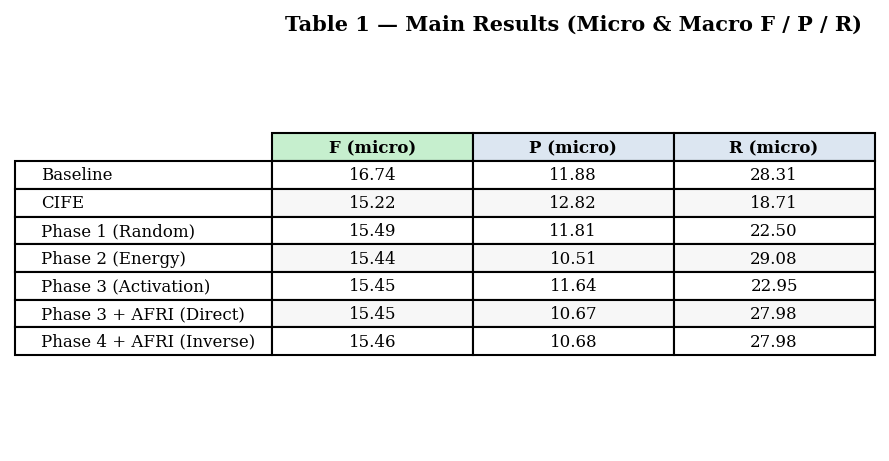

In [4]:
# ── Build display DataFrame ────────────────────────────────────────────────
RENAME = {
    "fmeasure":      "F (harm.)",
    "fmeasureavg":  "F (arith.)",
    "precision":     "P (harm.)",
    "recall":        "R (harm.)",
    "precisionavg": "P (arith.)",
    "recallavg":    "R (arith.)",
}

available_cols = [c for c in RENAME if c in df_final.columns]
df_t1 = df_final[available_cols].rename(columns=RENAME)

# Scale P/R columns that are 0-1 to 0-100 to match fmeasure scale
for col in ["P (harm.)", "R (harm.)", "P (arith.)", "R (arith.)"]:
    if col in df_t1.columns:
        if df_t1[col].dropna().max() <= 1.01:
            df_t1[col] = df_t1[col] * 100

display(df_t1.round(2))

# ── LaTeX export ───────────────────────────────────────────────────────────
latex_t1 = save_latex(
    df_t1.round(2),
    "tab_main.tex",
    caption=(
        "Main ablation results on DCASE 2024 Task 5 validation set. "
        "All values on a 0--100 scale. "
        "Bold = highest F-measure (harmonic subset mean)."
    ),
    label="tab:main_results",
    bold_best_col="F (harm.)",
)
print(latex_t1)

# ── Figure for PDF ─────────────────────────────────────────────────────────
fig_t1 = table_to_figure(
    df_t1.round(2),
    "Table 1 — Main Results (Harmonic & Arithmetic Subset-Mean F / P / R)",
    highlight_col="F (harm.)",
)
PDF_PAGES.append(fig_t1)
plt.show()

---
## Table 2 — Δ vs Baseline
Absolute gain (Δ) and relative gain (%) for every experiment over the Baseline.

In [5]:
baseline_row = df_t1.loc["Baseline"] if "Baseline" in df_t1.index else pd.Series(dtype=float)

df_t2 = pd.DataFrame(index=df_t1.index)

for col in df_t1.columns:
    base_val = baseline_row.get(col, np.nan)
    df_t2[f"Δ {col}"] = df_t1[col] - base_val
    df_t2[f"Δ% {col}"] = ((df_t1[col] - base_val) / base_val * 100).where(pd.notna(base_val) & base_val != 0)

# Keep only the F-measure deltas to avoid very wide tables
f_delta_cols = [c for c in df_t2.columns if "F" in c]
df_t2_display = df_t2[f_delta_cols].round(2)

display(df_t2_display)

latex_t2 = save_latex(
    df_t2_display,
    "tab_delta.tex",
    caption=(
        "Absolute ($\\Delta$) and relative ($\\Delta\\%%$) F-measure gains over the Baseline. "
        "Positive values indicate improvement."
    ),
    label="tab:delta_results",
)
print(latex_t2)

fig_t2 = table_to_figure(
    df_t2_display,
    "Table 2 — Δ vs Baseline (F-measure absolute and relative gain)",
)
PDF_PAGES.append(fig_t2)
plt.show()

TypeError: ufunc 'bitwise_and' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''

---
## Table 3 — Post-processing Effect
No-postproc best vs. best-with-postproc F-measure, and the postproc gain.

,No Post-proc F,Best Post-proc F,Gain
Baseline,11.29,16.74,5.45
CIFE,9.02,15.22,6.20
Phase 1 (Random),11.24,16.30,5.06
Phase 2 (Energy),11.23,16.38,5.15
Phase 3 (Activation),11.08,16.23,5.14
Phase 3 + AFRI (Direct),11.03,16.05,5.02
Phase 4 + AFRI (Inverse),11.03,16.17,5.14


  ✓ LaTeX written → ablation_tables/tab_postproc.tex
\begin{table}
\centering
\caption{Effect of post-processing. \emph{No Post-proc F}: best F-measure before any post-processing. \emph{Best Post-proc F}: F-measure after optimal post-processing threshold selection. \emph{Gain}: absolute improvement from post-processing.}
\label{tab:postproc_effect}
\begin{tabular}{lrrr}
\toprule
{} &  No Post-proc F &  Best Post-proc F &  Gain \\
\midrule
Baseline                 &           11.29 &             16.74 &  5.45 \\
CIFE                     &            9.02 &             15.22 &  6.20 \\
Phase 1 (Random)         &           11.24 &             16.30 &  5.06 \\
Phase 2 (Energy)         &           11.23 &             16.38 &  5.15 \\
Phase 3 (Activation)     &           11.08 &             16.23 &  5.14 \\
Phase 3 + AFRI (Direct)  &           11.03 &             16.05 &  5.02 \\
Phase 4 + AFRI (Inverse) &           11.03 &             16.17 &  5.14 \\
\bottomrule
\end{tabular}
\end{table}



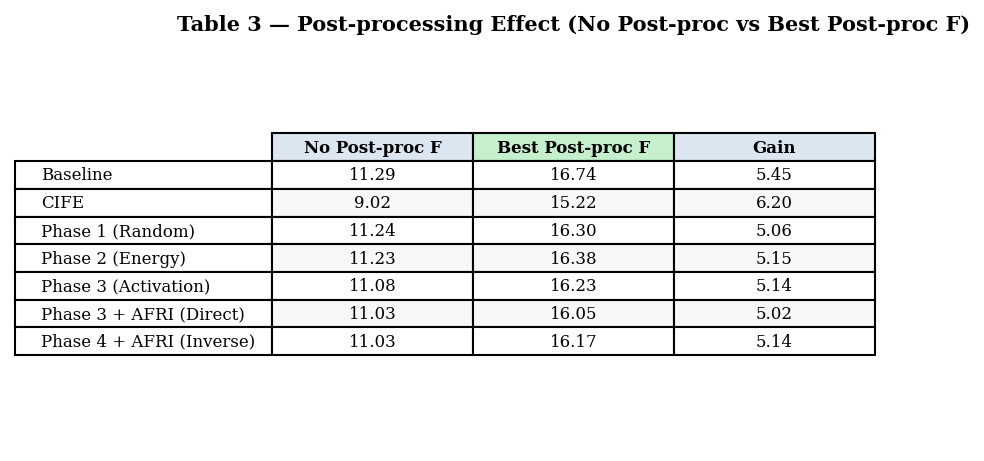

In [ ]:
# Best no-postproc F per experiment (max over all detection thresholds k)
if not df_nopost.empty and "fmeasure" in df_nopost.columns:
    no_post_best = (
        df_nopost.groupby("experiment")["fmeasure"]
        .max()
        .reindex(exp_order)
    )
else:
    no_post_best = pd.Series(np.nan, index=exp_order, name="fmeasure")

post_best = df_t1["F (harm.)"].reindex(exp_order) if "F (harm.)" in df_t1.columns \
            else pd.Series(np.nan, index=exp_order)

df_t3 = pd.DataFrame({
    "No Post-proc F": no_post_best.values,
    "Best Post-proc F": post_best.values,
    "Gain": post_best.values - no_post_best.values,
}, index=exp_order).round(2)

display(df_t3)

latex_t3 = save_latex(
    df_t3,
    "tab_postproc.tex",
    caption=(
        "Effect of post-processing. "
        "\\emph{No Post-proc F}: best F-measure before any post-processing. "
        "\\emph{Best Post-proc F}: F-measure after optimal post-processing threshold selection. "
        "\\emph{Gain}: absolute improvement from post-processing."
    ),
    label="tab:postproc_effect",
)
print(latex_t3)

fig_t3 = table_to_figure(
    df_t3,
    "Table 3 — Post-processing Effect (No Post-proc vs Best Post-proc F)",
    highlight_col="Best Post-proc F",
)
PDF_PAGES.append(fig_t3)
plt.show()

---
## Table 4 — Per-Species F-measure
Rows = species/subset, Columns = experiments.

,Baseline,CIFE,Phase 1 (Random),Phase 2 (Energy),Phase 3 (Activation),Phase 3 + AFRI (Direct),Phase 4 + AFRI (Inverse)
subset,,,,,,,
HB,0.550,0.57,0.56,0.56,0.56,0.56,0.56
ME,0.370,0.41,0.37,0.37,0.37,0.37,0.37
PB,0.140,0.11,0.16,0.16,0.16,0.16,0.16
PW,0.110,0.11,0.11,0.11,0.11,0.11,0.11
RD,0.300,0.30,0.30,0.30,0.30,0.30,0.30
Mean,0.294,0.30,0.30,0.30,0.30,0.30,0.30


  ✓ LaTeX written → ablation_tables/tab_per_species.tex
\begin{table}
\centering
\caption{Per-species mean F-measure across all experiments. Species subsets are inferred from audio filename prefixes. \emph{Mean} row = unweighted average across subsets.}
\label{tab:per_species}
\begin{tabular}{llrrrrrr}
\toprule
{} &       Baseline &  CIFE &  Phase 1 (Random) &  Phase 2 (Energy) &  Phase 3 (Activation) &  Phase 3 + AFRI (Direct) &  Phase 4 + AFRI (Inverse) \\
subset &                &       &                   &                   &                       &                          &                           \\
\midrule
HB     &  \textbf{0.55} &  0.57 &              0.56 &              0.56 &                  0.56 &                     0.56 &                      0.56 \\
ME     &           0.37 &  0.41 &              0.37 &              0.37 &                  0.37 &                     0.37 &                      0.37 \\
PB     &           0.14 &  0.11 &              0.16 &             

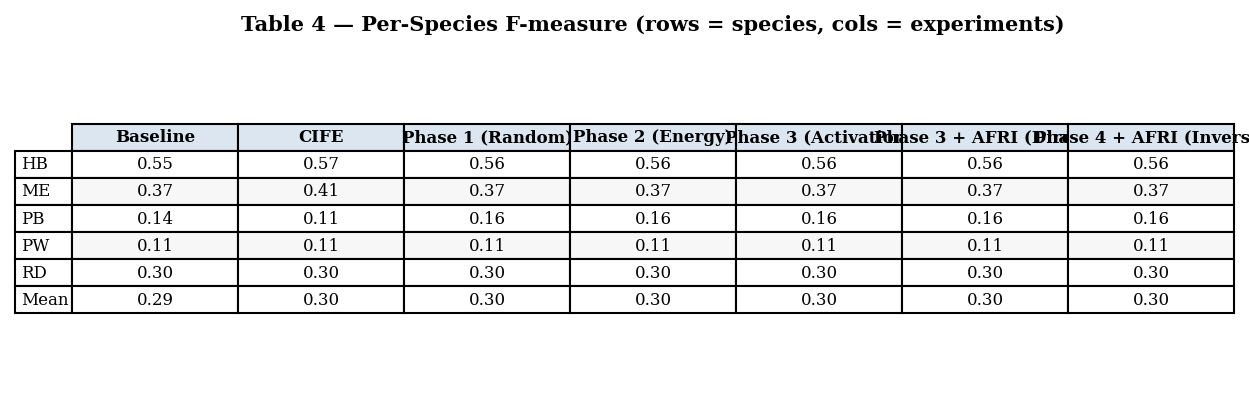

In [ ]:
if not df_perfile.empty:
    # Aggregate per subset × experiment
    df_t4_long = (
        df_perfile
        .groupby(["subset", "experiment"])["fmeasure"]
        .mean()
        .reset_index()
    )
    df_t4 = (
        df_t4_long
        .pivot(index="subset", columns="experiment", values="fmeasure")
        .reindex(columns=exp_order)
        .round(2)
    )
    df_t4.columns.name = None

    # Add row for overall mean
    df_t4.loc["Mean"] = df_t4.mean()

    display(df_t4)

    latex_t4 = save_latex(
        df_t4,
        "tab_per_species.tex",
        caption=(
            "Per-species F-measure, computed as the unweighted mean of the per-file "
            "F-measures within each subset. Note this is not the count-pooled "
            "per-subset F-measure reported elsewhere, and neither is the official "
            "DCASE score (a harmonic mean of the count-pooled per-subset values). "
            "Species subsets are inferred from audio filename prefixes. "
            "\\emph{Mean} row = unweighted arithmetic average across subsets."
        ),
        label="tab:per_species",
        bold_best_col="Baseline" if "Baseline" in df_t4.columns else None,
    )
    print(latex_t4)

    fig_t4 = table_to_figure(
        df_t4,
        "Table 4 — Per-Species F-measure (rows = species, cols = experiments)",
    )
    PDF_PAGES.append(fig_t4)
    plt.show()
else:
    print("Per-file data not available — Table 4 skipped.")

---
## Table 5 — Per-File TP / FP / FN (Winning Experiment)
Full per-file breakdown for the experiment with the highest F-measure (harmonic subset mean).

Best experiment: Baseline


,subset,TP,FP,FN,total_n_pos_events,precision,recall,fmeasure
filename,,,,,,,,
file_423_487.wav,HB,57,1,0,57,98.3,100.0,99.1
ME2.wav,ME,34,23,7,41,59.6,82.9,69.4
RD_06.wav,RD,280,425,81,361,39.7,77.6,52.5
RD_02.wav,RD,323,487,175,498,39.9,64.9,49.4
RD_05.wav,RD,85,100,76,161,45.9,52.8,49.1
BUK4_20171022_004304a.wav,PB,5,8,12,17,38.5,29.4,33.3
BUK4_20161031_232104a.wav,PB,25,26,152,177,49.0,14.1,21.9
pw14.wav,PW,44,346,6,50,11.3,88.0,20.0
BUK5_20180921_015906a.wav,PB,4,16,19,23,20.0,17.4,18.6


  ✓ LaTeX written → ablation_tables/tab_per_file.tex
\begin{table}
\centering
\caption{Per-file TP, FP, FN, Precision, Recall, and F-measure for the best-performing experiment (\emph{Baseline}). Sorted by F-measure descending.}
\label{tab:per_file}
\begin{tabular}{llrrrrrrl}
\toprule
{} & subset &   TP &    FP &   FN &  total_n_pos_events &  precision &  recall &        fmeasure \\
filename                  &        &      &       &      &                     &            &         &                 \\
\midrule
file_423_487.wav          &     HB &   57 &     1 &    0 &                  57 &      98.30 &  100.00 &  \textbf{99.10} \\
ME2.wav                   &     ME &   34 &    23 &    7 &                  41 &      59.60 &   82.90 &           69.40 \\
RD_06.wav                 &     RD &  280 &   425 &   81 &                 361 &      39.70 &   77.60 &           52.50 \\
RD_02.wav                 &     RD &  323 &   487 &  175 &                 498 &      39.90 &   64.90 &           

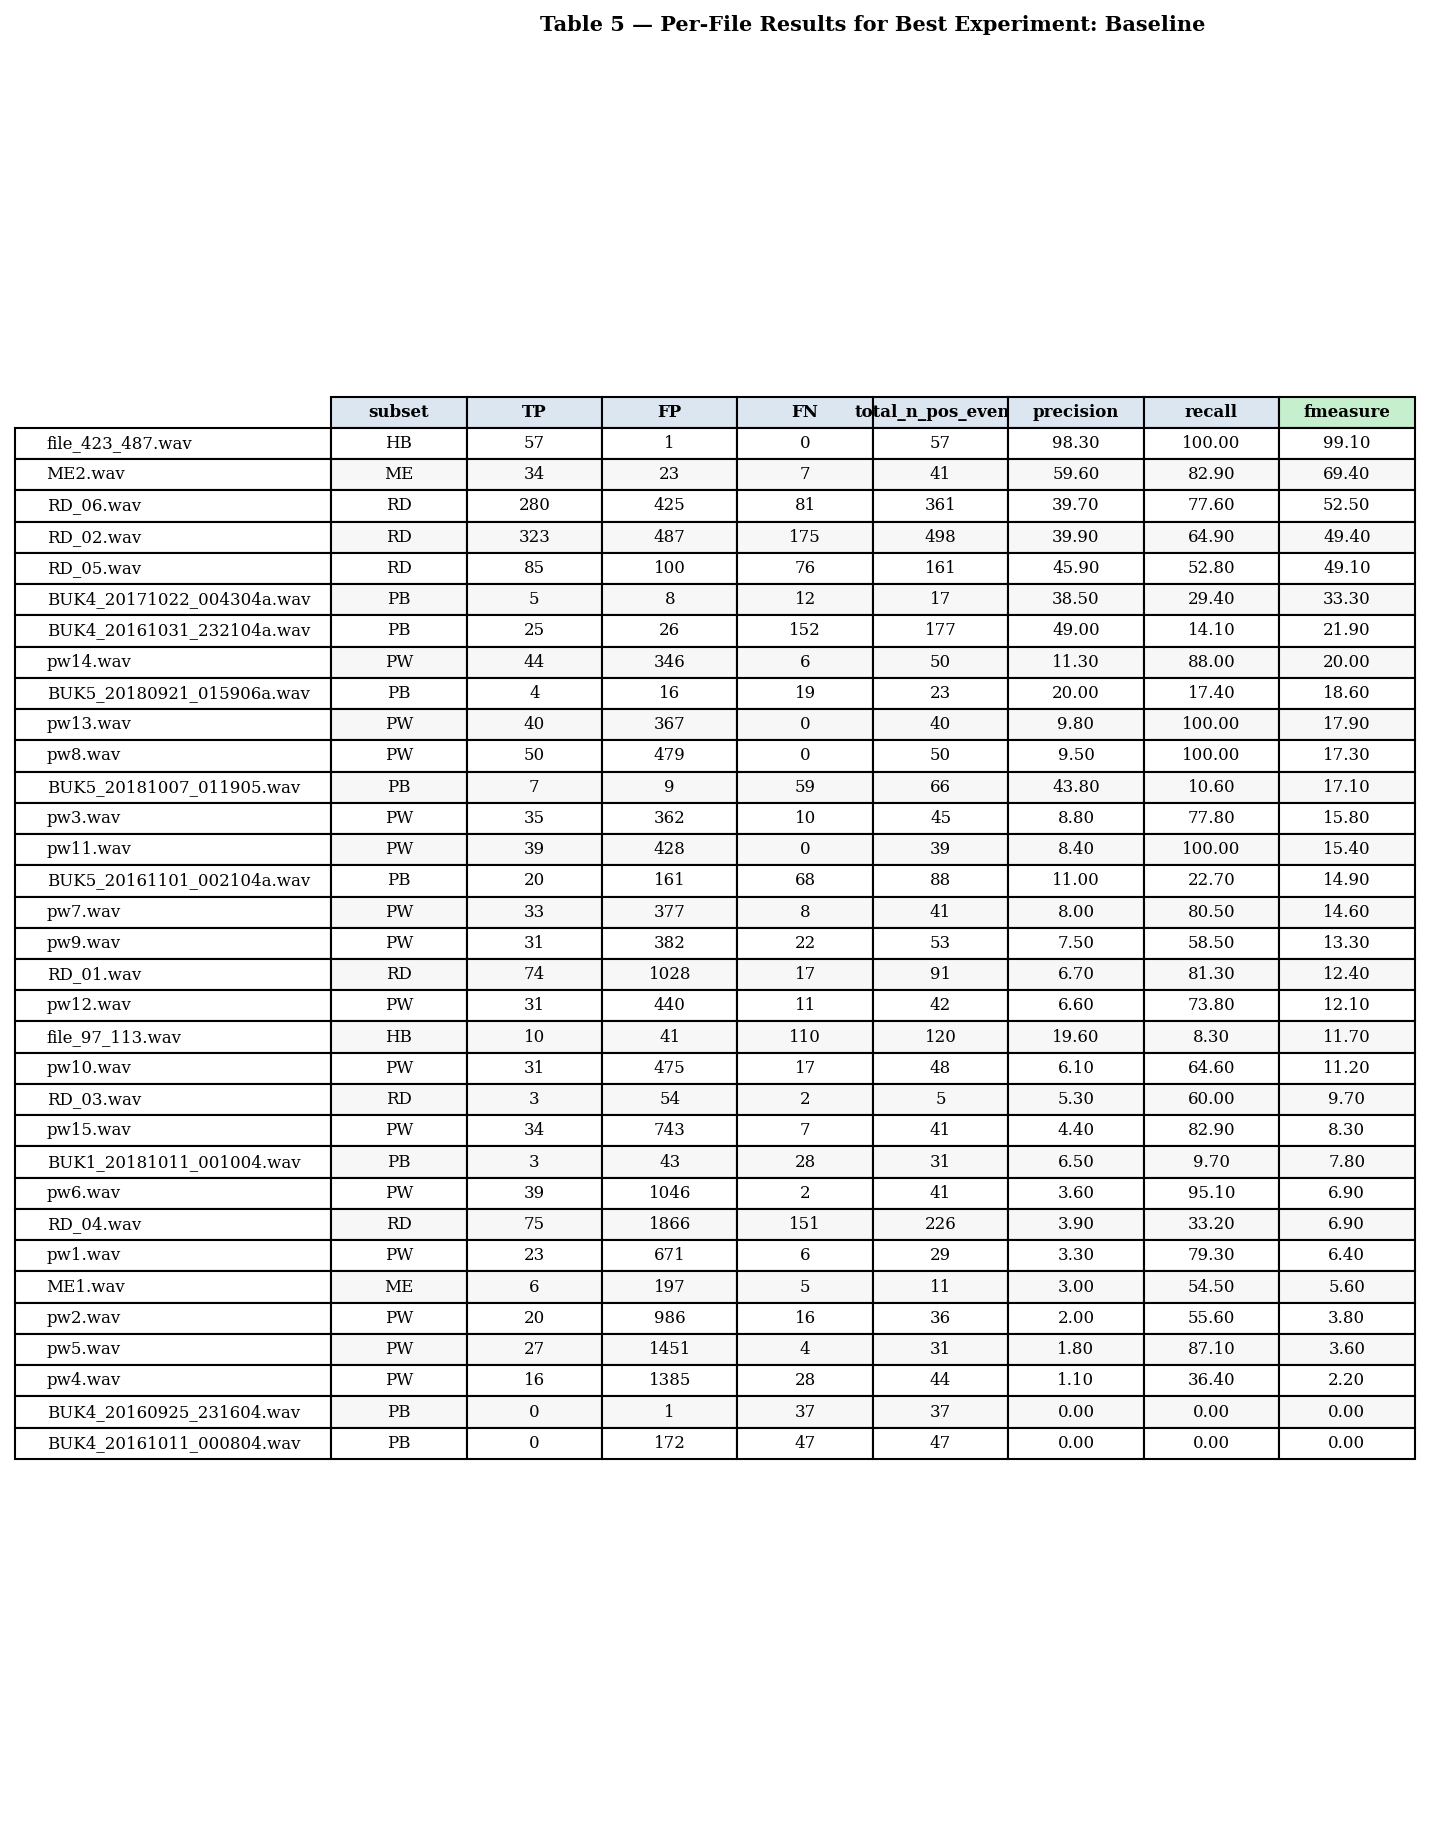

In [ ]:
if not df_perfile.empty and "F (harm.)" in df_t1.columns:
    best_exp = df_t1["F (harm.)"].idxmax(skipna=True)
    print(f"Best experiment: {best_exp}")

    df_t5 = (
        df_perfile[df_perfile["experiment"] == best_exp]
        [["filename", "subset", "TP", "FP", "FN",
          "total_n_pos_events", "precision", "recall", "fmeasure"]]
        .sort_values("fmeasure", ascending=False)
        .set_index("filename")
        .round(3)
    )
    # Scale P/R to 0-100
    for col in ["precision", "recall", "fmeasure"]:
        if df_t5[col].dropna().max() <= 1.01:
            df_t5[col] = (df_t5[col] * 100).round(2)

    display(df_t5)

    latex_t5 = save_latex(
        df_t5,
        "tab_per_file.tex",
        caption=(
            f"Per-file TP, FP, FN, Precision, Recall, and F-measure for the "
            f"best-performing experiment (\\emph{{{best_exp}}}). "
            "Sorted by F-measure descending."
        ),
        label="tab:per_file",
        bold_best_col="fmeasure",
    )
    print(latex_t5)

    fig_t5 = table_to_figure(
        df_t5,
        f"Table 5 — Per-File Results for Best Experiment: {best_exp}",
        highlight_col="fmeasure",
    )
    PDF_PAGES.append(fig_t5)
    plt.show()
else:
    print("Per-file data not available — Table 5 skipped.")

---
## Table 6 — Masking Phases vs Baseline
Focused comparison of the 5 masking experiments (Phases 1–3 + AFRI) with the Baseline row included.

,F (harm.),Δ F (harm.),P (harm.),R (harm.)
experiment,,,,
Baseline,16.74,0.00,11.88,28.31
Phase 1 (Random),16.30,-0.44,10.77,33.54
Phase 2 (Energy),16.38,-0.36,10.80,33.85
Phase 3 (Activation),16.23,-0.51,10.74,33.22


  ✓ LaTeX written → ablation_tables/tab_masking_phases.tex
\begin{table}
\centering
\caption{Comparison of frequency masking strategies against the Baseline. $\Delta$~F~(harm.) = absolute change in the harmonic subset-mean F-measure vs. Baseline. All strategies use aggressive coverage: $n_{\text{bands}}=4$, $p_{\text{mask}}=0.8$, $w_{\text{max}}=24$ mel bins.}
\label{tab:masking_phases}
\begin{tabular}{llrrr}
\toprule
{} &       F (harm.) &  Δ F (harm.) &  P (harm.) &  R (harm.) \\
experiment           &                 &              &            &            \\
\midrule
Baseline             &  \textbf{16.74} &         0.00 &      11.88 &      28.31 \\
Phase 1 (Random)     &           16.30 &        -0.44 &      10.77 &      33.54 \\
Phase 2 (Energy)     &           16.38 &        -0.36 &      10.80 &      33.85 \\
Phase 3 (Activation) &           16.23 &        -0.51 &      10.74 &      33.22 \\
\bottomrule
\end{tabular}
\end{table}



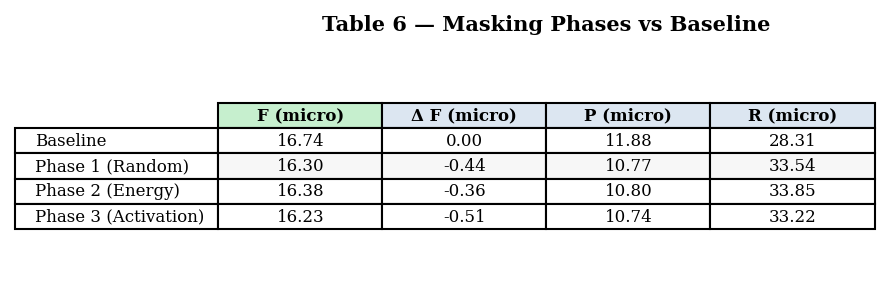

In [ ]:
masking_exps = [
    "Baseline",
    "Phase 1 (Random)",
    "Phase 2 (Energy)",
    "Phase 3 (Activation)",
    "AFRI Direct",
    "AFRI Inverse",
]
masking_exps_available = [e for e in masking_exps if e in df_t1.index]

df_t6 = df_t1.reindex(masking_exps_available).round(2)

# Add Δ vs Baseline column
if "F (harm.)" in df_t6.columns and "Baseline" in df_t6.index:
    base_f = df_t6.loc["Baseline", "F (harm.)"]
    df_t6.insert(1, "Δ F (harm.)", (df_t6["F (harm.)"] - base_f).round(2))

display(df_t6)

latex_t6 = save_latex(
    df_t6,
    "tab_masking_phases.tex",
    caption=(
        "Comparison of frequency masking strategies against the Baseline. "
        "$\\Delta$~F~(harm.) = absolute change in the harmonic subset-mean "
        "F-measure vs. Baseline. "
        "All strategies use aggressive coverage: "
        "$n_{\\text{bands}}=4$, $p_{\\text{mask}}=0.8$, $w_{\\text{max}}=24$ mel bins."
    ),
    label="tab:masking_phases",
    bold_best_col="F (harm.)",
)
print(latex_t6)

fig_t6 = table_to_figure(
    df_t6,
    "Table 6 — Masking Phases vs Baseline",
    highlight_col="F (harm.)",
)
PDF_PAGES.append(fig_t6)
plt.show()

---
## Table 7 — Experiment Configuration Summary
Human-readable config table for the thesis appendix.

,CIFE,Masking,Mode,$n$ bands,$p$ mask,Max width,AFRI,AFRI mode,Notes
Experiment,,,,,,,,,
Baseline,✗,✗,—,—,—,—,✗,—,No augmentation
CIFE,✓,✗,—,—,—,—,✗,—,Transformer at layer2→layer3; α=0.3
Phase 1 (Random),✗,✓,random,4,0.8,24,✗,—,SpecAugment-style uniform selection
Phase 2 (Energy),✗,✓,energy,4,0.8,24,✗,—,w\_energy=1.0; α\_energy=0.1 (new-weight EMA)
Phase 3 (Activation),✗,✓,activation,4,0.8,24,✗,—,w\_importance=1.0; α\_importance=0.9 (momentum...
AFRI Direct,✗,✓,activation,4,0.8,24,✓,direct,w\_afri=1.0; masks signal band
AFRI Inverse,✗,✓,activation,4,0.8,24,✓,inverse,w\_afri=1.0; masks background band


  ✓ LaTeX written → ablation_tables/tab_config.tex
\begin{table}
\centering
\caption{Experiment configuration summary. \emph{Max width} = maximum frequency band width in mel bins. \emph{AFRI mode}: direct = mask species signal band; inverse = mask background band. All masking experiments use aggressive coverage parameters. Old (conservative) parameters were: $n_{\text{bands}}=2$, $p_{\text{mask}}=0.5$, $w_{\text{max}}=16$.}
\label{tab:experiment_config}
\begin{tabular}{llllllllll}
\toprule
{} & CIFE & Masking &        Mode & $n$ bands & $p$ mask & Max width & AFRI & AFRI mode &                                              Notes \\
Experiment           &      &         &             &           &          &           &      &           &                                                    \\
\midrule
Baseline             &    ✗ &       ✗ &           — &         — &        — &         — &    ✗ &         — &                                    No augmentation \\
CIFE                 &    ✓ 

/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/.venv/lib/python3.7/site-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/.venv/lib/python3.7/site-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


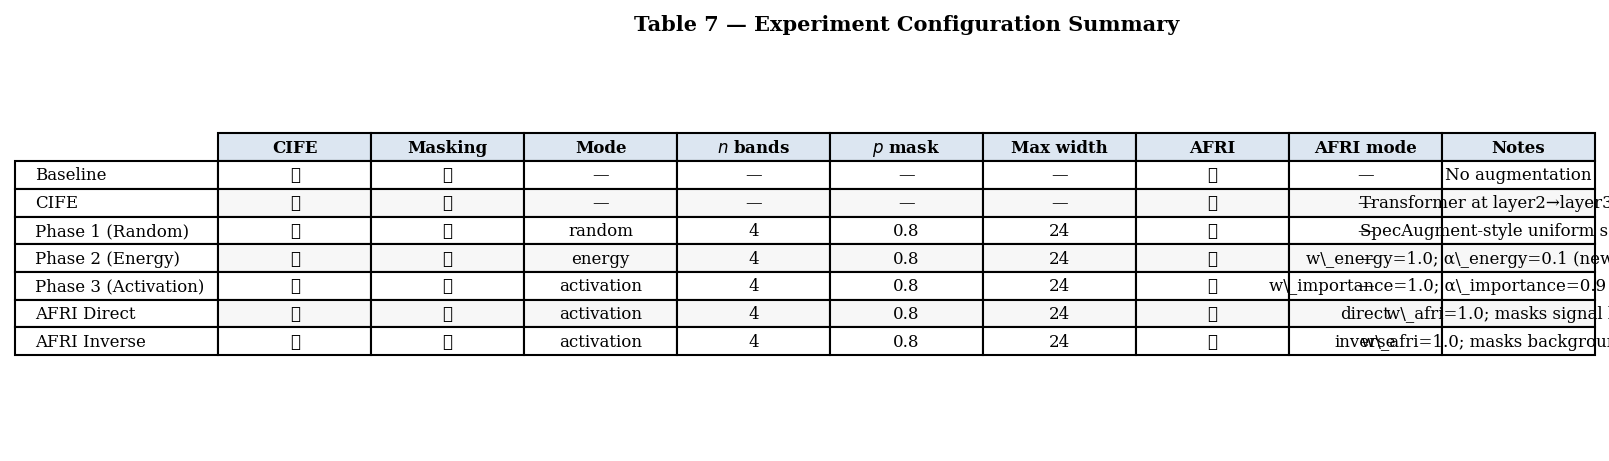

In [ ]:
config_rows = [
    {
        "Experiment":   "Baseline",
        "CIFE":         "✗",
        "Masking":      "✗",
        "Mode":         "—",
        "$n$ bands":    "—",
        "$p$ mask":     "—",
        "Max width":    "—",
        "AFRI":         "✗",
        "AFRI mode":    "—",
        "Notes":        "No augmentation",
    },
    {
        "Experiment":   "CIFE",
        "CIFE":         "✓",
        "Masking":      "✗",
        "Mode":         "—",
        "$n$ bands":    "—",
        "$p$ mask":     "—",
        "Max width":    "—",
        "AFRI":         "✗",
        "AFRI mode":    "—",
        "Notes":        "Transformer at layer2→layer3; α=0.3",
    },
    {
        "Experiment":   "Phase 1 (Random)",
        "CIFE":         "✗",
        "Masking":      "✓",
        "Mode":         "random",
        "$n$ bands":    "4",
        "$p$ mask":     "0.8",
        "Max width":    "24",
        "AFRI":         "✗",
        "AFRI mode":    "—",
        "Notes":        "SpecAugment-style uniform selection",
    },
    {
        "Experiment":   "Phase 2 (Energy)",
        "CIFE":         "✗",
        "Masking":      "✓",
        "Mode":         "energy",
        "$n$ bands":    "4",
        "$p$ mask":     "0.8",
        "Max width":    "24",
        "AFRI":         "✗",
        "AFRI mode":    "—",
        "Notes":        "w\_energy=1.0; α\_energy=0.1 (new-weight EMA)",
    },
    {
        "Experiment":   "Phase 3 (Activation)",
        "CIFE":         "✗",
        "Masking":      "✓",
        "Mode":         "activation",
        "$n$ bands":    "4",
        "$p$ mask":     "0.8",
        "Max width":    "24",
        "AFRI":         "✗",
        "AFRI mode":    "—",
        "Notes":        "w\_importance=1.0; α\_importance=0.9 (momentum EMA)",
    },
    {
        "Experiment":   "AFRI Direct",
        "CIFE":         "✗",
        "Masking":      "✓",
        "Mode":         "activation",
        "$n$ bands":    "4",
        "$p$ mask":     "0.8",
        "Max width":    "24",
        "AFRI":         "✓",
        "AFRI mode":    "direct",
        "Notes":        "w\_afri=1.0; masks signal band",
    },
    {
        "Experiment":   "AFRI Inverse",
        "CIFE":         "✗",
        "Masking":      "✓",
        "Mode":         "activation",
        "$n$ bands":    "4",
        "$p$ mask":     "0.8",
        "Max width":    "24",
        "AFRI":         "✓",
        "AFRI mode":    "inverse",
        "Notes":        "w\_afri=1.0; masks background band",
    },
]

df_t7 = pd.DataFrame(config_rows).set_index("Experiment")
display(df_t7)

latex_t7 = save_latex(
    df_t7,
    "tab_config.tex",
    caption=(
        "Experiment configuration summary. "
        "\\emph{Max width} = maximum frequency band width in mel bins. "
        "\\emph{AFRI mode}: direct = mask species signal band; "
        "inverse = mask background band. "
        "All masking experiments use aggressive coverage parameters. "
        "Old (conservative) parameters were: $n_{\\text{bands}}=2$, "
        "$p_{\\text{mask}}=0.5$, $w_{\\text{max}}=16$."
    ),
    label="tab:experiment_config",
)
print(latex_t7)

fig_t7 = table_to_figure(
    df_t7,
    "Table 7 — Experiment Configuration Summary",
)
PDF_PAGES.append(fig_t7)
plt.show()

---
## Export — Merge all tables into a single PDF

In [ ]:
if PDF_PAGES:
    with pdf_backend.PdfPages(PDF_OUTPUT) as pdf:
        for fig in PDF_PAGES:
            pdf.savefig(fig, bbox_inches="tight")
            plt.close(fig)

        # PDF metadata
        d = pdf.infodict()
        d["Title"]   = "DCASE 2024 Task 5 — Ablation Study Result Tables"
        d["Author"]  = "Masters Thesis"
        d["Subject"] = "Few-Shot Bioacoustic Sound Event Detection"
        d["Keywords"] = "DCASE, few-shot, bioacoustic, ablation, frequency masking, AFRI, CIFE"

    print(f"\n✓ Merged PDF written → {PDF_OUTPUT}")
    print(f"  Pages: {len(PDF_PAGES)}")
else:
    print("No figures were generated — PDF not written.")

# ── List all generated files ───────────────────────────────────────────────
print("\nGenerated files:")
for f in sorted(OUTPUT_DIR.iterdir()):
    size_kb = f.stat().st_size / 1024
    print(f"  {f.name:45s}  {size_kb:6.1f} KB")

/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/.venv/lib/python3.7/site-packages/ipykernel_launcher.py:4: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from current font.
  after removing the cwd from sys.path.
/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/.venv/lib/python3.7/site-packages/ipykernel_launcher.py:4: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from current font.
  after removing the cwd from sys.path.



✓ Merged PDF written → ablation_tables/ablation_results_all_tables.pdf
  Pages: 6

Generated files:
  ablation_results_all_tables.pdf                  57.3 KB
  tab_config.tex                                    2.0 KB
  tab_main.tex                                      0.9 KB
  tab_masking_phases.tex                            0.9 KB
  tab_per_file.tex                                  4.5 KB
  tab_per_species.tex                               1.5 KB
  tab_postproc.tex                                  0.9 KB


---
## Appendix — Raw LaTeX Strings
Run this cell to print all `.tex` contents in one block for easy copy-paste into the thesis.

In [ ]:
tex_files = sorted(OUTPUT_DIR.glob("*.tex"))

for tex_path in tex_files:
    print(f"\n% {'='*60}")
    print(f"% FILE: {tex_path.name}")
    print(f"% {'='*60}")
    print(tex_path.read_text(encoding="utf-8"))